In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pandas
import os

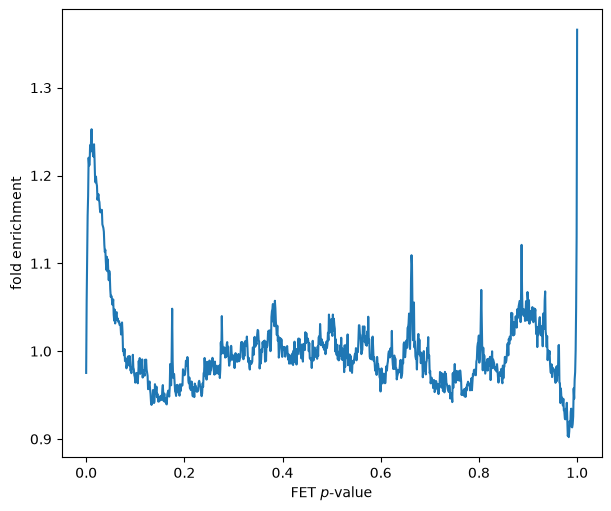

In [3]:
sums = np.loadtxt("../../results/FET_pvals/sum_p_bins.tsv")
fig, ax = plt.subplots(1, 1, figsize=(6, 5), layout="constrained")
ax.plot(np.linspace(0,1,1000), sums/np.mean(sums))
#ax.set_yscale("log")
ax.set_xlabel("FET $p$-value")
ax.set_ylabel("fold enrichment")
plt.savefig("../../figures/FET_p_values_unlinked.png", dpi=244)

In [6]:
df = pandas.read_csv("../../results/FET_pvals/sig_sites.tsv", sep="\\s+",
                    names=["chrom1", "position1", "chrom2", "position2", "p", "EE", "EA", "AE", "AA"])
ps = np.array(df["p"])

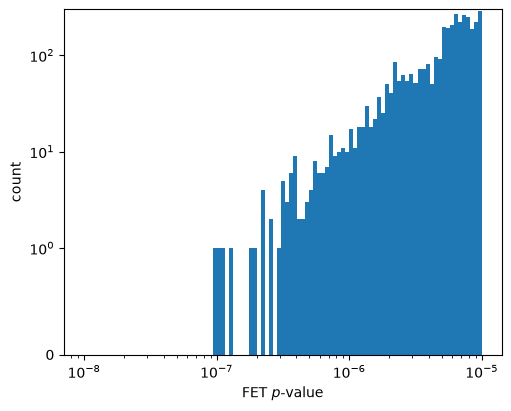

In [8]:
bins = np.logspace(-8, -5, 100)
fig, ax = plt.subplots(1, 1, figsize=(5, 4), layout="constrained")
ax.hist(ps, bins=bins)
ax.set_xscale("log")
ax.set_yscale("symlog", linthresh=1)
ax.set_ylabel("count")
ax.set_xlabel("FET $p$-value")
plt.savefig("../../figures/FET_small_p_values_unlinked.png", dpi=244)

In [9]:
print(df.iloc[np.argmin(ps)])

chrom1             X
position1    5732280
chrom2            3L
position2     477057
p                0.0
EE               957
EA                95
AE                21
AA                16
Name: 715, dtype: object


In [10]:
EE = 957
EA = 95
AE = 21
AA = 16
N = EE + EA + AE + AA
A1 = (AE + AA) / N
A2 = (AA + EA) / N
E1 = (EE + EA) / N
E2 = (AE + EE) / N
print(E1 * E2 * N)
print(E1 * A2 * N)
print(A1 * E2 * N)
print(A1 * A2 * N)

944.7713498622588
107.22865013774104
33.22865013774104
3.771349862258953
